# Week 5 — Machine Learning Fundamentals & Regression

## From prepared molecular data to a predictive model

In this notebook we adapt the Week 5 regression workflow to the `properties.csv` molecular-properties dataset.

**Research question:** What relationship exists between molecular weight and lipophilicity (Mannhold LogP), and can other molecular descriptors improve prediction of LogP?

### Learning goals
- Distinguish features (`X`) from the target (`y`)
- Implement the train/test split
- Fit a linear regression model
- Interpret coefficients and predictions
- Understand residuals, loss, and least squares
- Calculate and interpret basic regression metrics
- Compare a one-feature model with a multiple-feature model
- Explore generalisation, underfitting and overfitting


## 1. The modelling workflow

Our supervised-learning workflow is:

**Dataset → Features `X` + Target `y` → Train/Test Split → Train Model → Predictions → Error → Evaluate Generalisation**

For this dataset, we ask:

> **Can we predict molecular lipophilicity (Mannhold LogP) from molecular characteristics?**

We first use **Molecular Weight** as one feature, then extend the model to several molecular descriptors.


## 2. Load the libraries

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline


## 3. Load the molecular-properties dataset

The dataset contains chemical compounds and molecular descriptors. Our target is `Mannhold LogP`, a measure of lipophilicity.

For the first model, we will use `Molecular Weight` as the single predictor.


In [4]:
df = pd.read_csv(r"C:\COLLEGE\CSC1171\Week 1\week3-DataIntro\notebooks\properties.csv")

df.head()


,index,row ID,Molecule,Molecule name,Mannhold LogP,Atomic Polarizabilities,Aromatic Atoms Count,Aromatic Bonds Count,Element Count,Bond Polarizabilities,...,XLogP,Zagreb Index,Molecular Formula,Formal Charge,Formal Charge (pos),Formal Charge (neg),Heavy Atoms Count,Molar Mass,SP3 Character,Rotatable Bonds Count (non terminal)
0,0,Row0,N,H3N,1.35,3.100379,0,0,4,1.299621,...,0.000,0,H3N,0,0,0,1,17.030525,0.000000,0
1,1,Row1,O=C(O)c1c(OC(=O)C)cccc1,C9H8O4,2.01,24.382344,6,6,21,12.577656,...,1.422,60,C9H8O4,0,0,0,13,180.157769,0.047619,3
2,2,Row2,C#C,C2H2,1.68,4.853586,0,0,4,2.186414,...,0.418,2,C2H2,0,0,0,2,26.037353,0.000000,0
3,3,Row3,P(=O)(OP(=O)(OC[C@H]1O[C@@H](n2c3ncnc(c3nc2)N)...,C10H16N5O13P3,0.25,55.084688,9,10,47,55.749312,...,-5.533,170,C10H16N5O13P3,0,0,0,31,507.181476,0.106383,8
4,4,Row4,S1C([C@H](C(=O)O)N2[C@H]1[C@H](NC(=O)[C@H](N)c...,C16H19N3O4S,2.34,50.237067,6,6,43,27.904933,...,-1.732,132,C16H19N3O4S,0,0,0,24,349.406463,0.162791,4


## 4. Inspect the dataset

Before modelling, we still need to check the shape, data types and missing values.

Some columns contain `#NUM!` values, so we convert those entries to missing values and convert the molecular measurements used in the model to numeric values.


In [5]:
print("Shape:", df.shape)

print("\nData types:")
print(df.dtypes)

print("\nMissing values before cleaning:")
print(df.isna().sum().sort_values(ascending=False).head(15))

# Convert #NUM! to missing values
df = df.replace("#NUM!", np.nan)

numeric_columns = [
    "Molecular Weight",
    "Mannhold LogP",
    "Hydrogen Bond Acceptors",
    "Hydrogen Bond Donors",
    "Topological Polar Surface Area",
    "Rotatable Bonds Count",
    "SP3 Character"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("\nMissing values after cleaning:")
print(df[numeric_columns].isna().sum())

df[numeric_columns].describe().round(2)


Shape: (15166, 34)

Data types:
index                                       int64
row ID                                     object
Molecule                                   object
Molecule name                              object
Mannhold LogP                             float64
Atomic Polarizabilities                    object
Aromatic Atoms Count                        int64
Aromatic Bonds Count                        int64
Element Count                               int64
Bond Polarizabilities                      object
Bond Count                                  int64
Eccentric Connectivity Index              float64
Fragment Complexity                       float64
VABC Volume Descriptor                     object
Hydrogen Bond Acceptors                     int64
Hydrogen Bond Donors                        int64
Largest Chain                               int64
Largest Pi Chain                            int64
Petitjean Number                          float64
Rotatable Bonds Co

,Molecular Weight,Mannhold LogP,Hydrogen Bond Acceptors,Hydrogen Bond Donors,Topological Polar Surface Area,Rotatable Bonds Count,SP3 Character
count,15163.00,15166.00,15166.00,15166.00,15159.00,15166.00,15166.00
mean,326.57,2.49,3.99,1.84,81.87,8.31,0.15
std,312.69,1.19,6.93,3.74,132.41,10.89,0.10
min,1.01,-4.81,0.00,0.00,0.00,0.00,0.00
25%,181.09,1.68,1.00,0.00,29.46,3.00,0.07
50%,287.11,2.45,3.00,1.00,57.28,6.00,0.15
75%,391.97,3.22,5.00,2.00,97.74,10.00,0.22
max,10300.59,47.44,229.00,90.00,3678.99,280.00,1.00


## 5. Features `X` and target `y`

We want to predict `Mannhold LogP`.

- **Target `y`** = `Mannhold LogP`
- **Feature `X`** = `Molecular Weight`

We start with one feature so that we can clearly see what simple linear regression is doing.


In [6]:
model_data = df[["Molecular Weight", "Mannhold LogP"]].dropna()

X = model_data[["Molecular Weight"]]
y = model_data["Mannhold LogP"]

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (15163, 1)
y shape: (15163,)


## 6. Explore the relationship

Before fitting a model, visualise the relationship between molecular weight and Mannhold LogP.

The original dataset contains some extreme values, so a transparent scatter plot can become crowded. A regression plot still lets us see the overall linear trend.


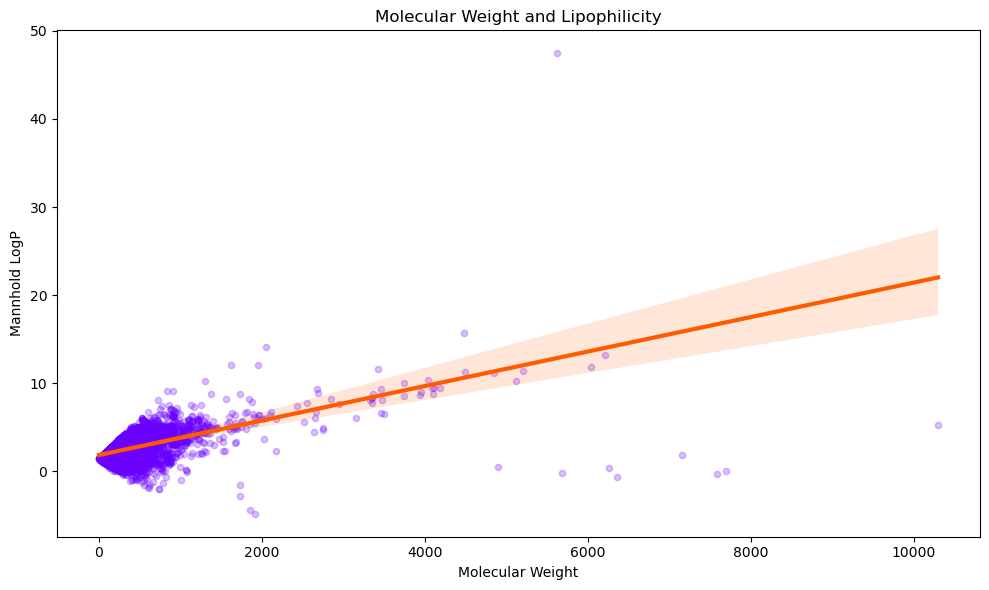

In [7]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=model_data,
    x="Molecular Weight",
    y="Mannhold LogP",
    scatter_kws={"alpha": 0.25, "s": 20, "color": "#6A00FF"},
    line_kws={"color": "#FF5A00", "linewidth": 3}
)

plt.xlabel("Molecular Weight")
plt.ylabel("Mannhold LogP")
plt.title("Molecular Weight and Lipophilicity")
plt.tight_layout()
plt.show()


## 7. Train vs. test data

We split the observations into:

- **Training data:** used to learn the model parameters
- **Test data:** kept separate so we can assess performance on unseen compounds

We use an 80/20 split and `random_state=42` so the split is reproducible.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


Training observations: 12130
Test observations: 3033


## 8. Train a linear regression model

Our model is:

$$\hat{y} = b_0 + b_1x$$

Here:

- `b0` = intercept
- `b1` = coefficient / slope

The model learns these parameters using ordinary least squares.


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])


Intercept: 1.7974056963663845
Coefficient: 0.002125464280444668


## 9. Interpret the model

The model has the form:

$$\hat{y} = b_0 + b_1 \times \text{Molecular Weight}$$

The coefficient tells us how the **predicted Mannhold LogP** changes for a one-unit increase in molecular weight.

This is an association in the fitted model; it does not show that increasing molecular weight causes lipophilicity to increase.


In [10]:
print(
    f"Model equation: LogP = {model.intercept_:.3f} + "
    f"{model.coef_[0]:.5f} × Molecular Weight"
)

print(
    f"Predicted LogP change for +100 molecular-weight units: "
    f"{100 * model.coef_[0]:.3f}"
)


Model equation: LogP = 1.797 + 0.00213 × Molecular Weight
Predicted LogP change for +100 molecular-weight units: 0.213


### Is the intercept meaningful?

The intercept is the predicted LogP when molecular weight is 0. A compound with molecular weight of 0 is not meaningful here, so the intercept is mainly needed to position the regression line.

This is a useful reminder to check whether an intercept represents a realistic situation before interpreting it literally.


## 10. Make predictions

The trained model can now predict Mannhold LogP for compounds in the test set that were not used to fit the model.


In [11]:
y_pred = model.predict(X_test)

results = pd.DataFrame({
    "Molecular Weight": X_test["Molecular Weight"].values,
    "Actual LogP": y_test.values,
    "Predicted LogP": y_pred
})

results.head(10)


,Molecular Weight,Actual LogP,Predicted LogP
0,321.782204,0.69,2.481342
1,186.115698,2.56,2.192988
2,314.065119,2.01,2.464940
3,620.378950,4.87,3.115999
4,302.094294,3.33,2.439496
5,57.955300,1.24,1.920588
6,127.009185,1.68,2.067359
7,290.137890,2.23,2.414083
8,70.041865,1.79,1.946277
9,356.088244,3.11,2.554259


## 11. Visualise the fitted regression line

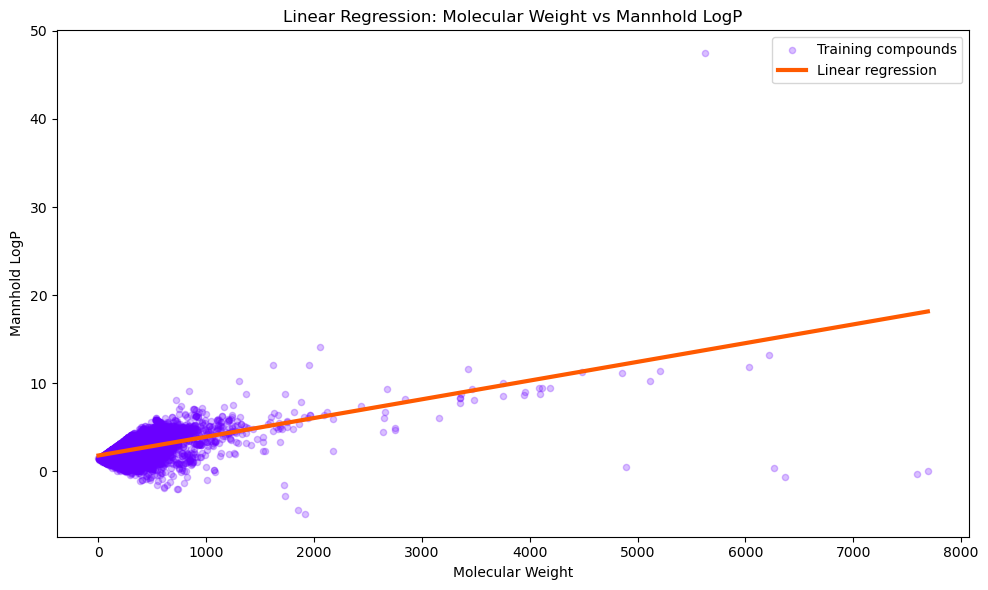

In [12]:
x_line = pd.DataFrame({
    "Molecular Weight": np.linspace(
        X_train["Molecular Weight"].min(),
        X_train["Molecular Weight"].max(),
        200
    )
})

y_line = model.predict(x_line)

plt.figure(figsize=(10, 6))
plt.scatter(
    X_train["Molecular Weight"],
    y_train,
    alpha=0.25,
    s=20,
    color="#6A00FF",
    label="Training compounds"
)
plt.plot(
    x_line["Molecular Weight"],
    y_line,
    color="#FF5A00",
    linewidth=3,
    label="Linear regression"
)

plt.xlabel("Molecular Weight")
plt.ylabel("Mannhold LogP")
plt.title("Linear Regression: Molecular Weight vs Mannhold LogP")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Residuals

A residual is:

$$e_i = y_i - \hat{y}_i$$

It is the difference between the actual LogP and the model's predicted LogP.


In [13]:
results["Residual"] = y_test.values - y_pred

results.head(10)


,Molecular Weight,Actual LogP,Predicted LogP,Residual
0,321.782204,0.69,2.481342,-1.791342
1,186.115698,2.56,2.192988,0.367012
2,314.065119,2.01,2.464940,-0.454940
3,620.378950,4.87,3.115999,1.754001
4,302.094294,3.33,2.439496,0.890504
5,57.955300,1.24,1.920588,-0.680588
6,127.009185,1.68,2.067359,-0.387359
7,290.137890,2.23,2.414083,-0.184083
8,70.041865,1.79,1.946277,-0.156277
9,356.088244,3.11,2.554259,0.555741


### Visualising residuals

Ideally, residuals should be scattered around 0 without a strong systematic pattern.


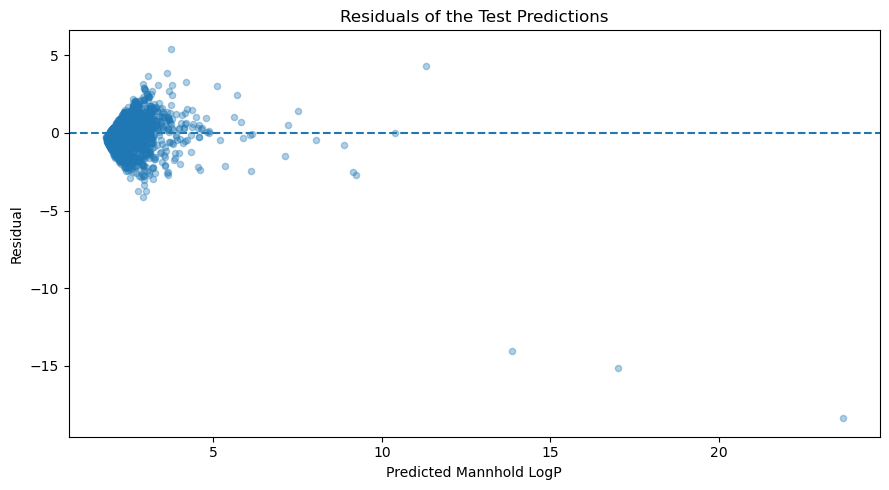

In [14]:
plt.figure(figsize=(9, 5))
plt.scatter(
    results["Predicted LogP"],
    results["Residual"],
    alpha=0.35,
    s=20
)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted Mannhold LogP")
plt.ylabel("Residual")
plt.title("Residuals of the Test Predictions")
plt.tight_layout()
plt.show()


## 13. How does the model choose a line?

Linear regression chooses parameters that keep the residuals small overall. In ordinary least squares, residuals are squared before being added together.

This gives the **sum of squared errors (SSE)**. `LinearRegression` performs this optimisation when `.fit()` is called.


In [15]:
train_predictions = model.predict(X_train)
train_residuals = y_train.values - train_predictions
train_sse = np.sum(train_residuals ** 2)

print(f"Training sum of squared errors: {train_sse:,.2f}")


Training sum of squared errors: 12,628.37


## 14. Regression evaluation

We use four common regression metrics:

- **MAE:** average absolute prediction error
- **MSE:** average squared prediction error
- **RMSE:** square root of MSE, in the original LogP units
- **R²:** compares the model with a baseline that always predicts the average LogP

We calculate the metrics on both training and test data so we can compare how well the model fits known observations and how well it generalises to unseen compounds.


In [16]:
def regression_metrics(y_true, y_hat):
    mse = mean_squared_error(y_true, y_hat)
    return {
        "MAE": mean_absolute_error(y_true, y_hat),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R²": r2_score(y_true, y_hat),
    }

metrics_1f = pd.DataFrame({
    "Training": regression_metrics(y_train, model.predict(X_train)),
    "Test": regression_metrics(y_test, y_pred),
})

metrics_1f.round(3)


,Training,Test
MAE,0.707,0.697
MSE,1.041,1.027
RMSE,1.020,1.013
R²,0.281,0.182


## 15. Next step: add more features

Our first model used only `Molecular Weight`. We can now use several molecular descriptors to predict Mannhold LogP.

We will use:

- `Molecular Weight`
- `Hydrogen Bond Acceptors`
- `Hydrogen Bond Donors`
- `Topological Polar Surface Area`
- `Rotatable Bonds Count`
- `SP3 Character`

We deliberately do **not** include `XLogP` in this first multiple-regression model because it is another LogP descriptor and is very closely related to our target. Including it could make the prediction task less informative by giving the model another direct lipophilicity measure.


In [17]:
features = [
    "Molecular Weight",
    "Hydrogen Bond Acceptors",
    "Hydrogen Bond Donors",
    "Topological Polar Surface Area",
    "Rotatable Bonds Count",
    "SP3 Character"
]

multi_data = df[features + ["Mannhold LogP"]].dropna()

X_multi = multi_data[features]
y_multi = multi_data["Mannhold LogP"]

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(
    X_multi, y_multi, test_size=0.2, random_state=42
)

model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)

y_pred_m = model_multi.predict(X_test_m)

comparison = pd.DataFrame({
    "Molecular Weight only": regression_metrics(
        y_test, model.predict(X_test)
    ),
    "Multiple molecular features": regression_metrics(
        y_test_m, y_pred_m
    )
})

comparison.round(3)


,Molecular Weight only,Multiple molecular features
MAE,0.697,0.460
MSE,1.027,0.462
RMSE,1.013,0.680
R²,0.182,0.645


### Interpret the multiple-regression coefficients

In a multiple linear regression model, each coefficient describes the association between that feature and predicted LogP **while holding the other included features constant**.

Because molecular descriptors can be strongly correlated with one another, individual coefficients should be interpreted carefully.


In [18]:
coefficients = pd.Series(
    model_multi.coef_,
    index=features
).sort_values(ascending=False)

print(f"Intercept: {model_multi.intercept_:.4f}")
coefficients


Intercept: 1.2166


SP3 Character                     2.499903
Hydrogen Bond Donors              0.139674
Rotatable Bonds Count             0.019911
Molecular Weight                  0.004612
Topological Polar Surface Area   -0.010363
Hydrogen Bond Acceptors          -0.045477
dtype: float64

## 16. Do more features always help?

Adding useful features can improve predictions, but adding irrelevant or noisy features can make a model fit the training data better without improving its performance on unseen data.

The key comparison is therefore the **test performance**, not just the training performance.


In [19]:
print("One-feature model")
print(regression_metrics(y_test, model.predict(X_test)))

print("\nMultiple-feature model")
print(regression_metrics(y_test_m, y_pred_m))


One-feature model
{'MAE': 0.6972910615073925, 'MSE': 1.0268766405455154, 'RMSE': np.float64(1.0133492194428906), 'R²': 0.18224364586289554}

Multiple-feature model
{'MAE': 0.45996542253263095, 'MSE': 0.46229292318779924, 'RMSE': np.float64(0.6799212624913265), 'R²': 0.6452660007553139}


## 17. Underfitting and overfitting: a visual example

The Week 5 notebook uses a small toy dataset to demonstrate underfitting and overfitting. This section is kept as a general machine-learning demonstration rather than forcing a high-degree polynomial onto the molecular dataset.


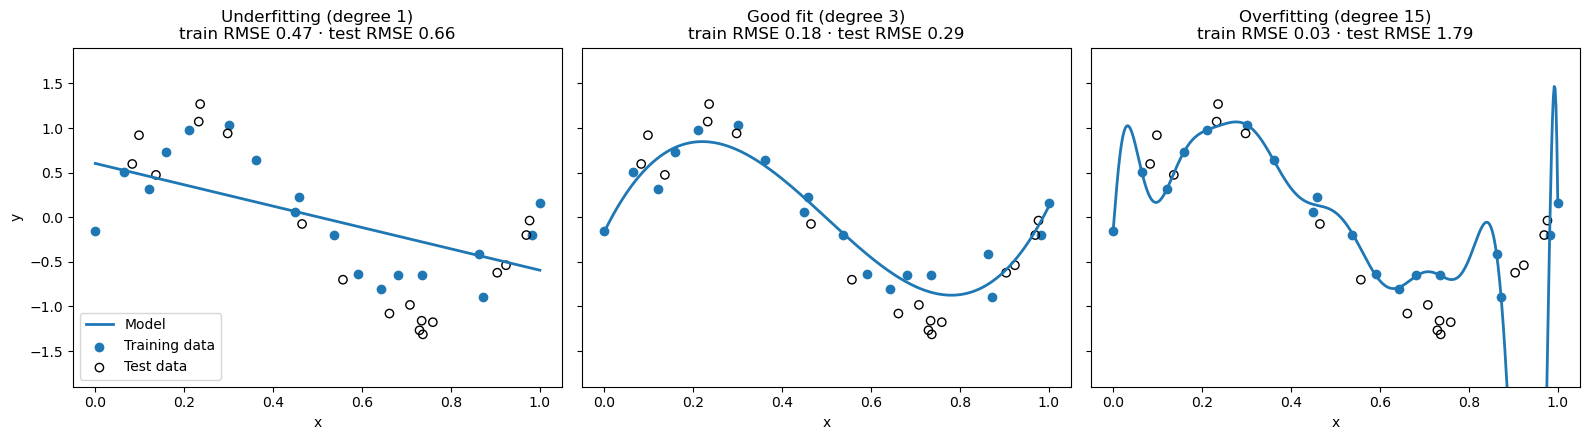

In [20]:
toy_rng = np.random.default_rng(39)
true_curve = lambda x: np.sin(2 * np.pi * x)

x_toy_train = np.sort(
    np.clip(np.linspace(0, 1, 18) + toy_rng.normal(0, 0.02, 18), 0, 1)
)
y_toy_train = true_curve(x_toy_train) + toy_rng.normal(0, 0.25, 18)

x_toy_test = np.sort(
    toy_rng.uniform(x_toy_train.min(), x_toy_train.max(), 18)
)
y_toy_test = true_curve(x_toy_test) + toy_rng.normal(0, 0.25, 18)

def poly_model(degree):
    return make_pipeline(
        PolynomialFeatures(degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    ).fit(x_toy_train[:, None], y_toy_train)

def rmse(m, x, y_true):
    return np.sqrt(mean_squared_error(y_true, m.predict(x[:, None])))

x_grid = np.linspace(x_toy_train.min(), x_toy_train.max(), 500)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)

for ax, (degree, label) in zip(
    axes,
    [(1, "Underfitting"), (3, "Good fit"), (15, "Overfitting")]
):
    m = poly_model(degree)

    ax.plot(
        x_grid,
        m.predict(x_grid[:, None]),
        linewidth=2,
        label="Model"
    )
    ax.scatter(
        x_toy_train,
        y_toy_train,
        label="Training data"
    )
    ax.scatter(
        x_toy_test,
        y_toy_test,
        facecolors="none",
        edgecolors="k",
        label="Test data"
    )

    ax.set_ylim(-1.9, 1.9)
    ax.set_title(
        f"{label} (degree {degree})\n"
        f"train RMSE {rmse(m, x_toy_train, y_toy_train):.2f} · "
        f"test RMSE {rmse(m, x_toy_test, y_toy_test):.2f}"
    )
    ax.set_xlabel("x")

axes[0].set_ylabel("y")
axes[0].legend(loc="lower left")

plt.tight_layout()
plt.show()


## Key Takeaways

- **Regression** predicts a numerical target: features `X` are inputs and `y` is the value to predict.
- In this dataset, `Mannhold LogP` is the target.
- `Molecular Weight` has a positive relationship with LogP, but one feature alone does not explain all the variation.
- A **residual** is the difference between an actual value and a prediction.
- MAE, RMSE and R² help us judge prediction performance on unseen compounds.
- Multiple molecular descriptors can be compared with a one-feature model.
- Adding more features does not automatically guarantee better generalisation.
- The coefficients describe associations in the fitted model; they do not by themselves establish causation.
